In [1]:
import accelerate
print(accelerate.__version__)

1.15.0


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Before fine-tuning:
Recall@1: 0.8333
Recall@3: 1.0000
MRR: 0.9167


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


After fine-tuning:
Recall@1: 0.8333
Recall@3: 1.0000
MRR: 0.9167


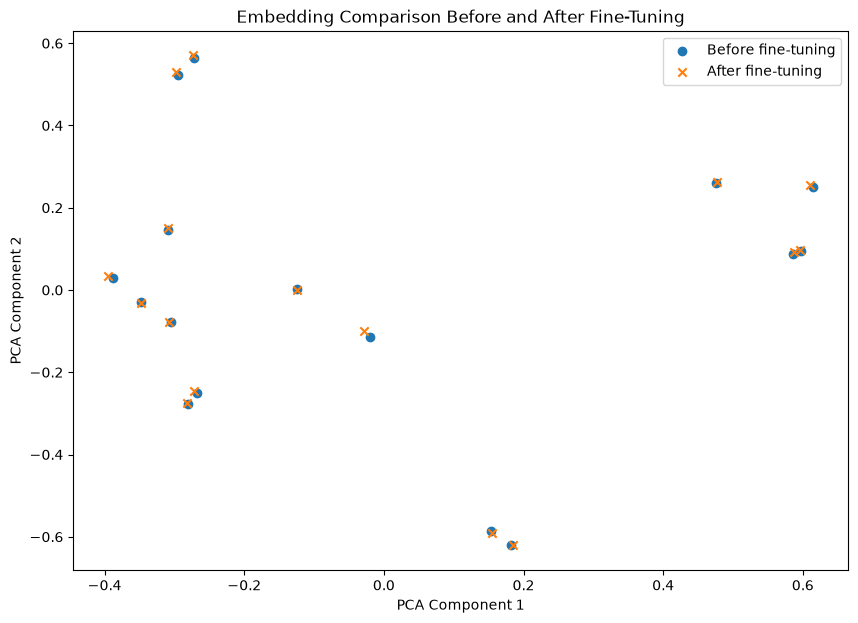

In [3]:
import torch
import matplotlib.pyplot as plt

from datasets import Dataset
from sentence_transformers import (SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments)
from sentence_transformers.losses import MultipleNegativesRankingLoss
from sklearn.decomposition import PCA

model_name = "sentence-transformers/all-MiniLM-L6-v2"
epochs = 1
batch_size = 4
learning_rate = 2e-5

training_data = {
    "anchor": [
        "How does gradient descent update model parameters?",
        "What is the purpose of a convolutional neural network?",
        "How do transformers process sequences?",
        "What does a tokenizer do to text?",
        "How is classification accuracy calculated?",
        "What is the purpose of dropout during training?",
        "How do embeddings represent the meaning of text?",
        "What is the role of a learning rate?",
    ],
    "positive": [
        "Gradient descent updates parameters using gradients of the loss.",
        "Convolutional neural networks learn spatial features from data.",
        "Transformers use attention mechanisms to process input sequences.",
        "A tokenizer converts text into tokens or token identifiers.",
        "Classification accuracy measures the fraction of correct predictions.",
        "Dropout randomly suppresses activations during training.",
        "Embeddings encode text as numerical vectors.",
        "The learning rate controls the size of parameter updates.",
    ],
}

train_dataset = Dataset.from_dict(training_data)

documents = [
    "An optimizer updates neural network parameters using gradients to reduce a loss function.",
    "Convolutional neural networks identify patterns such as edges and shapes in images.",
    "Self-attention allows transformer models to determine relationships between tokens.",
    "Tokenization splits text into tokens that can be mapped to numerical IDs.",
    "Classification accuracy is the proportion of predictions that match the true labels.",
    "Dropout reduces overfitting by randomly disabling some activations during training.",
    "Text embeddings represent words or sentences as numerical vectors.",
    "The learning rate determines the size of each optimization step.",
    "Backpropagation calculates gradients of the loss with respect to model parameters.",
    "A validation dataset helps assess how well a model performs on data not used for training.",
    "Batch size determines how many training examples are processed in one batch.",
    "An activation function introduces nonlinearity into a neural network."
]

evaluation_queries = [
    "How are neural network weights adjusted to reduce errors?",
    "Which transformer mechanism identifies relationships between tokens?",
    "How is text split into units before entering a language model?",
    "What controls the size of an optimizer's update?",
    "Why do we use validation data during model development?",
    "What helps a neural network learn complex nonlinear patterns?"
]

relevant_indices = [0, 2, 3, 7, 9, 11]

def retrieval_documents(model, queries, corpus, top_k=3):
    queries_embeddings = model.encode(
        queries,
        convert_to_tensor = True,
        normalize_embeddings = True,
        show_progress_bar = False
    )

    document_embeddings = model.encode(
        corpus,
        convert_to_tensor=True,
        normalize_embeddings=True,
        show_progress_bar=False
    )

    similarities = queries_embeddings @ document_embeddings.T

    top_k = min(top_k, len(corpus))

    rankings = torch.argsort(
        similarities, dim=1, descending=True
    )[:,:top_k]

    return rankings.cpu().tolist()

def evaluate_retrieval(model, queries, corpus, relevant_indices):
    rankings = retrieval_documents(model, queries, corpus, top_k=3)

    recall_at_1 = []
    recall_at_3 = []
    reciprocal_rank = []

    for ranking, relevant_index in zip(rankings, relevant_indices):
        recall_at_1.append(1 if relevant_index in ranking[:1] else 0)

        recall_at_3.append(1 if relevant_index in ranking[:3] else 0)

        if relevant_index in ranking:
            rank = ranking.index(relevant_index) + 1
            reciprocal_rank.append(1 / rank)
        else:
            reciprocal_rank.append(0)
        
    return {
            "Recall@1": (sum(recall_at_1)/ len(queries)),
            "Recall@3": (sum(recall_at_3)/ len(queries)),
            "MRR": (sum(reciprocal_rank) / len(queries))
    }

model = SentenceTransformer(model_name)

before_results = evaluate_retrieval(
    model,
    evaluation_queries,
    documents,
    relevant_indices
)

print("Before fine-tuning:")

for metric, score in before_results.items():
    print(f"{metric}: {score:.4f}")


texts_to_plot = training_data["anchor"] + training_data["positive"]

before_embeddings = model.encode(
    texts_to_plot,
    normalize_embeddings=True,
    show_progress_bar=False
)

loss = MultipleNegativesRankingLoss(model)

training_args = SentenceTransformerTrainingArguments(
    output_dir = "minilm-contrastive-training",
    num_train_epochs = epochs,
    per_device_train_batch_size = batch_size,
    learning_rate = learning_rate,
    warmup_steps = 0.1,
    fp16=False,
    bf16=False,
    report_to = "none",
    save_strategy = "no"
)

trainer = SentenceTransformerTrainer(
    model = model,
    args = training_args,
    loss = loss,
    train_dataset = train_dataset
)

trainer.train()
model.save("minilm-contrastive-finetuned")

after_embeddings = model.encode(
    texts_to_plot,
    normalize_embeddings=True,
    show_progress_bar=False
)

after_results = evaluate_retrieval(
    model,
    evaluation_queries,
    documents,
    relevant_indices
)

print("\nAfter fine-tuning:")
for metric, score in after_results.items():
    print(f"{metric}: {score:.4f}")

texts_to_plot = training_data["anchor"] + training_data["positive"]

embeddings = model.encode(
    texts_to_plot,
    normalize_embeddings = True,
    show_progress_bar = False
)

pca = PCA(n_components=2)

# Fit PCA on the baseline embeddings.
before_2d = pca.fit_transform(before_embeddings)

# Project the fine-tuned embeddings using the same PCA.
after_2d = pca.transform(after_embeddings)

plt.figure(figsize=(10, 7))

plt.scatter(
    before_2d[:, 0],
    before_2d[:, 1],
    label="Before fine-tuning",
    marker="o"
)

plt.scatter(
    after_2d[:, 0],
    after_2d[:, 1],
    label="After fine-tuning",
    marker="x"
)

plt.title("Embedding Comparison Before and After Fine-Tuning")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.show()



In [ ]:
training_args = SentenceTransformerTrainingArguments(
    output_dir = "minilm-contrastive-training",
    num_train_epochs = epochs,
    per_device_train_batch_size = batch_size,
    learning_rate = learning_rate,
    warmup_ratio = 0.1,
    fp16=False,
    bf16=False,
    report_to = "none",
    save_strategy = "no"
)

trainer = SentenceTransformerTrainer(
    model = model,
    args = training_args,
    train_dataset = train_dataset,
    loss = loss
)

trainer.train()

model.save("minilm-contrastive-finetuned")

after_results = evaluate_retrieval(
    model,
    evaluation_queries,
    documents,
    relevant_document_indices
)

print("\nAfter fine-tuning:")
for metric, score in after_results.items():
    print(f"{metric}: {score:.4f}")


texts_to_plot = training_data["anchor"] + training_data["positive"]

embeddings = model.encode(
    texts_to_plot,
    normalize_embeddings = True,
    show_progress_bar = False
)

pca = PCA(n_components=2)
reduced_embeddings = pca.fit_transform(embeddings)

plt.figure(10, 7)

plt.scatter(
    reduced_embeddings[:, 0],
    reduced_embeddings[:, 1]
)

plt.title("Text Embeddings After Fine-Tuning")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()


In [ ]:
import torch
import matplotlib.pyplot as plt

from datasets import Dataset
from sentence_transformers import (SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments)
from sentence_transformers.losses import MultipleNegativesRankingLoss
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity



model_name = "sentence-transformers/all-MiniLM-L6-v2"

batch_size = 4
epochs = 1
learning_rate = 2e-5


training_data = {
    "anchor": [
        "How does gradient descent update model parameters?",
        "What is the purpose of a convolutional neural network?",
        "How do transformers process sequences?",
        "What does a tokenizer do to text?",
        "How is classification accuracy calculated?",
        "What is the purpose of dropout during training?",
        "How do embeddings represent the meaning of text?",
        "What is the role of a learning rate?",
    ],
    "positive": [
        "Gradient descent updates parameters using gradients of the loss.",
        "Convolutional neural networks learn spatial features from data.",
        "Transformers use attention mechanisms to process input sequences.",
        "A tokenizer converts text into tokens or token identifiers.",
        "Classification accuracy measures the fraction of correct predictions.",
        "Dropout randomly suppresses activations during training.",
        "Embeddings encode text as numerical vectors.",
        "The learning rate controls the size of parameter updates.",
    ],
}

train_dataset = Dataset.from_dict(training_data)


documents = [
    "Gradient descent updates parameters using gradients of the loss.",
    "Convolutional neural networks learn spatial features from data.",
    "Transformers use attention mechanisms to process input sequences.",
    "A tokenizer converts text into tokens or token identifiers.",
    "Classification accuracy measures the fraction of correct predictions.",
    "Dropout randomly suppresses activations during training.",
    "Embeddings encode text as numerical vectors.",
    "The learning rate controls the size of parameter updates.",
]

evaluation_queries = [
    "How are neural network weights updated?",
    "How does attention help a transformer?",
    "How can text be converted into tokens?",
    "What does the learning rate control?",
]

relevant_document_indices = [0, 2, 3, 7]

def retrieve_documents(model, queries, corpus, top_k=3):
    query_embeddings = model.encode(
        queries,
        convert_to_tensor=True,
        normalize_embeddings=True,
        show_progress_bar=False
    )
    document_embeddings = model.encode(
        corpus,
        convert_to_tensor=True,
        normalize_embeddings=True,
        show_progress_bar=False
    )

    similarities = query_embeddings @ document_embeddings.T

    top_k = min(top_k, len(corpus))

    rankings = torch.argsort(
        similarities, dim=1, descending=True
    )[:, :top_k]

    return rankings.cpu().tolist()

def evaluate_retrieval(model, queries, corpus, relevant_indices):
    rankings = retrieve_documents(model, queries, corpus, top_k=3)

    recall_at_1 = []
    recall_at_3 = []
    reciprocal_ranks = []

    for ranking, relevant_index in zip(rankings, relevant_indices):
        recall_at_1.append(1 if relevant_index in ranking[:1] else 0)
        print(recall_at_1)


        recall_at_3.append(1 if relevant_index in ranking[:3] else 0)
        print(recall_at_3)

        if relevant_index in ranking:
            rank = ranking.index(relevant_index) + 1
            reciprocal_ranks.append(1 / rank)

        else:
            reciprocal_ranks.append(0)

    return {
        "Recall@1": sum(recall_at_1) / len(queries),
        "Recall@3": sum(recall_at_3) / len(queries),
        "MRR": sum(reciprocal_ranks) / len(queries)
    }

model = SentenceTransformer(model_name)

before_results = evaluate_retrieval(
    model,
    evaluation_queries,
    documents,
    relevant_document_indices
)

print("Before fine-tuning:")
for metric, score in before_results.items():
    print(f"{metric}: {score:.4f}")


loss = MultipleNegativesRankingLoss(model)

training_args = SentenceTransformerTrainingArguments(
    output_dir = "minilm-contrastive-training",
    num_train_epochs = epochs,
    per_device_train_batch_size = batch_size,
    learning_rate = learning_rate,
    warmup_ratio = 0.1,
    fp16=False,
    bf16=False,
    report_to = "none",
    save_strategy = "no"
)

trainer = SentenceTransformerTrainer(
    model = model,
    args = training_args,
    train_dataset = train_dataset,
    loss = loss
)

trainer.train()

model.save("minilm-contrastive-finetuned")

after_results = evaluate_retrieval(
    model,
    evaluation_queries,
    documents,
    relevant_document_indices
)

print("\nAfter fine-tuning:")
for metric, score in after_results.items():
    print(f"{metric}: {score:.4f}")


texts_to_plot = training_data["anchor"] + training_data["positive"]

embeddings = model.encode(
    texts_to_plot,
    normalize_embeddings = True,
    show_progress_bar = False
)

pca = PCA(n_components=2)
reduced_embeddings = pca.fit_transform(embeddings)

plt.figure(10, 7)

plt.scatter(
    reduced_embeddings[:, 0],
    reduced_embeddings[:, 1]
)

plt.title("Text Embeddings After Fine-Tuning")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()


In [10]:
import torch
from sentence_transformers import SentenceTransformer
from sentence_transformers.util import cos_sim

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

query = "How can I measure whether my search engine finds relevant information?"

documents = ["Contrastive Learning learns by differentiating between similar and dissimilar pairs of data points. It aims to bring similar data points closer in the embedding space while pushing dissimilar ones apart. This is typically achieved using a contrastive loss function, which encourages the model to minimize the distance between positive pairs (similar) and maximize the distance between negative pairs (dissimilar).",
          "Machine learning is a field of study that gives computers the ability to learn without being explicitly programmed.",
          "Triplet loss compares an anchor, a positive example, and a negative example.",
          "Deep learning is part of a broader family of machine learning methods based on artificial neural networks with representation learning.",
          "Neural networks are computing systems vaguely inspired by the biological neural networks that constitute animal brains.",
          "Fine-tuning adapts a pretrained model to a particular task or dataset.",
          "Recall at k measures whether relevant results appear among the first k retrieved items."]

document_embeddings = model.encode(
    documents,
    convert_to_tensor = True,
    normalize_embeddings=True
)

def search_documents(query, top_k=3):
    query_embedding = model.encode(
        query,
        convert_to_tensor=True,
        normalize_embeddings=True
    )

    scores = cos_sim(
        query_embedding,
        document_embeddings
    )[0]

    results = scores.topk(
        k=min(top_k, len(documents))
    )

    for score, index in zip(results.values, results.indices):
        print(f"Score: {score.item():.3f}")
        print(f"Document: {documents[index]}")
        print()


search_documents(query, top_k=3)




evaluation_data = [
    {
        "query" : "What is Contrastive Learning?",
        "relevant_doc" : 0
    },
    {
        "query" : "How can I adapt a pretrained model?",
        "relevant_doc" : 5
    },
    {
        "query" : "How do I measure search quality?",
        "relevant_doc" : 6
    }
]



def recall_at_k(query, relevant_doc, k=3):
    query_embedding = model.encode(
        query,
        convert_to_tensor=True,
        normalize_embeddings=True
    )

    scores = cos_sim(
        query_embedding,
        document_embeddings
    )[0]

    top_results = scores.topk(
        k = min(k, len(documents))
    )

    retrieved_indices = top_results.indices.tolist()
    return int(relevant_doc in retrieved_indices)


recall_1_scores = []
recall_3_scores = []
for item in evaluation_data:
    query = item["query"]
    relevant_doc = item["relevant_doc"]

    recall_1_scores.append(recall_at_k(query, relevant_doc, k=1))
    recall_3_scores.append(recall_at_k(query, relevant_doc, k=3))

    print("Mean Recall@1 = ", (sum(recall_1_scores)/(len(recall_1_scores))))
    print("Mean Recall@3 = ", (sum(recall_3_scores)/(len(recall_3_scores))))
    print()


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Score: 0.348
Document: Recall at k measures whether relevant results appear among the first k retrieved items.

Score: 0.194
Document: Fine-tuning adapts a pretrained model to a particular task or dataset.

Score: 0.182
Document: Machine learning is a field of study that gives computers the ability to learn without being explicitly programmed.

Mean Recall@1 =  1.0
Mean Recall@3 =  1.0

Mean Recall@1 =  1.0
Mean Recall@3 =  1.0

Mean Recall@1 =  1.0
Mean Recall@3 =  1.0



In [ ]:
import torch
from sentence_transformers import SentenceTransformer
from sentence_transformers.util import (
    dot_score, normalize_embeddings, semantic_search
)

embedder = SentenceTransformer('all-MiniLM-L6-v2')

corpus = [
    "Machine learning is a field of study that gives computers the ability to learn without being explicitly programmed.",
    "Deep learning is part of a broader family of machine learning methods based on artificial neural networks with representation learning.",
    "Neural networks are computing systems vaguely inspired by the biological neural networks that constitute animal brains.",
    "Mars rovers are robotic vehicles designed to travel on the surface of Mars to collect data and perform experiments.",
    "The James Webb Space Telescope is the largest optical telescope in space, designed to conduct infrared astronomy.",
    "SpaceX's Starship is designed to be a fully reusable transportation system capable of carrying humans to Mars and beyond.",
    "Global warming is the long-term heating of Earth's climate system observed since the pre-industrial period due to human activities.",
    "Renewable energy sources include solar, wind, hydro, and geothermal power that naturally replenish over time.",
    "Carbon capture technologies aim to collect CO2 emissions before they enter the atmosphere and store them underground.",
]

corpus_embeddings = embedder.encode(corpus, convert_to_tensor = True) 

queries = [
    "How do artificial neural networks work?",
    "What technology is used for modern space exploration?",
    "How can we address climate change challenges?",
]

queries_embedding = embedder.encode(queries, convert_to_tensor = True)


corpus_embeddings = corpus_embeddings.to("cuda")
corpus_embeddings = normalize_embeddings(corpus_embeddings)

queries_embedding = queries_embedding.to("cuda")
queries_embedding = normalize_embeddings(queries_embedding)

hits = semantic_search(
    queries_embedding,
    corpus_embeddings,
    top_k = 5,
    score_function = dot_score
)

hits

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[[{'corpus_id': 2, 'score': 0.5925880670547485},
  {'corpus_id': 1, 'score': 0.5288357734680176},
  {'corpus_id': 0, 'score': 0.46465954184532166},
  {'corpus_id': 3, 'score': 0.1380504071712494},
  {'corpus_id': 8, 'score': 0.09121253341436386},
  {'corpus_id': 4, 'score': 0.07294292002916336},
  {'corpus_id': 7, 'score': 0.06244836747646332},
  {'corpus_id': 6, 'score': 0.046523578464984894},
  {'corpus_id': 5, 'score': 0.019551750272512436}],
 [{'corpus_id': 3, 'score': 0.3753741979598999},
  {'corpus_id': 5, 'score': 0.3668856918811798},
  {'corpus_id': 4, 'score': 0.34517401456832886},
  {'corpus_id': 7, 'score': 0.2625322937965393},
  {'corpus_id': 8, 'score': 0.2275022268295288},
  {'corpus_id': 6, 'score': 0.16675767302513123},
  {'corpus_id': 1, 'score': 0.1573893129825592},
  {'corpus_id': 0, 'score': 0.12964403629302979},
  {'corpus_id': 2, 'score': 0.09625361859798431}],
 [{'corpus_id': 6, 'score': 0.37598717212677},
  {'corpus_id': 8, 'score': 0.3144227862358093},
  {'corp

In [11]:
from sentence_transformers import CrossEncoder

model = CrossEncoder("cross-encoder/stsb-distilroberta-base")

query = "A healthy relationship"

corpus = ["Shrejal is my Cute Little Girlfriend.",
             "I am the Boyfriend of Shrejal.",
             "We are a Lovely Couple.",
             "Shrejal enjoys cooking traditional Indian dishes on weekends.",
             "The weather in Lucknow is quite pleasant today.",
             "Python is a powerful programming language for machine learning.",
             "I need to buy some groceries after finishing this work.",
             "The solar system consists of eight planets orbiting the sun."]

ranks = model.rank(query, corpus)
print("Query : ",query)

for rank in ranks:
    print(f"{rank['score']:.2f}\t{sentences[rank['corpus_id']]}")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Query :  A healthy relationship
0.41	We are a Lovely Couple.
0.19	I am the Boyfriend of Shrejal.
0.15	Shrejal is my Cute Little Girlfriend.
0.12	The weather in Lucknow is quite pleasant today.
0.04	Python is a powerful programming language for machine learning.
0.03	The solar system consists of eight planets orbiting the sun.
0.02	Shrejal enjoys cooking traditional Indian dishes on weekends.
0.02	I need to buy some groceries after finishing this work.


In [ ]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-V2")

sentences = ["Shrejal is my Cute Little Girlfriend.",
             "I am the Boyfriend of Shrejal.",
             "We are a Lovely Couple."]

embeddings = model.encode(sentences)
print(embeddings.shape)

similarities = model.similarity(embeddings, embeddings)
similarities

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

(3, 384)


tensor([[1.0000, 0.8028, 0.3253],
        [0.8028, 1.0000, 0.3513],
        [0.3253, 0.3513, 1.0000]])